# 02 · How style success changes over time

The prediction period should be:
- **long enough** for success to show a pattern rather than noise,
- **aligned with the business**, i.e. the interval during which a range of styles is produced and sold,
- **short enough** that the two years of history contain enough of them to learn from.

This notebook looks at the success score at the finest level, **per style per day**, to see trends, seasonality and noise.
Then it measures how reliable the score is for different period lengths.

Daily score = the same formula as the season-level score, computed per day: each style is compared with the
other styles of its category on that day. The full price is the article's highest price **up to that day**.

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data_science").is_dir())
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import warnings
warnings.filterwarnings("ignore", category=RuntimeWarning)   # correlations of all-zero series

from data_science.data import load_articles, load_transactions
from data_science.features.style import add_style_columns
from data_science.features.success import success_scores

pd.set_option("display.width", 200, "display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})

styled = add_style_columns(load_articles())
tx = load_transactions(columns=["t_dat", "article_id", "price", "sales_channel_id"])
START, END = tx.t_dat.min(), tx.t_dat.max()
print(f"{len(tx):,} transactions, {START.date()} → {END.date()} ({(END - START).days + 1} days)")

31,788,324 transactions, 2018-09-20 → 2020-09-22 (734 days)


In [2]:
# Days with no store sales at all (COVID closures): store sales are missing from the data on these days
store_units = tx[tx.sales_channel_id == 1].groupby("t_dat").size().reindex(pd.date_range(START, END), fill_value=0)
no_store = store_units[store_units == 0].index
COVID = (no_store.min(), no_store.max())
print(f"days with zero store sales: {len(no_store)}, from {COVID[0].date()} to {COVID[1].date()}")

days with zero store sales: 45, from 2020-03-20 to 2020-05-05


## 1. Daily success score per style

In [3]:
# article-day sales, with the full price = highest price of the article up to that day
ad = tx.groupby(["article_id", "t_dat"]).agg(revenue=("price", "sum"), units=("price", "size"),
                                             max_price=("price", "max")).reset_index()
ad["ref_price"] = ad.sort_values("t_dat").groupby("article_id").max_price.cummax()
ad["full_price_revenue"] = ad.units * ad.ref_price
ad = ad.merge(styled[["article_id", "style_id", "style_name", "group_id", "product_type_name"]], on="article_id")


def score(df, keys):
    """Success score per style for each value of `keys` (e.g. a day or a window)."""
    s = df.groupby(keys + ["style_id", "style_name", "group_id"], as_index=False)[["revenue", "full_price_revenue"]].sum()
    s["adjusted_revenue"] = s.revenue ** 2 / s.full_price_revenue
    g = s.groupby(keys + ["group_id"]).adjusted_revenue
    s["success_score"] = s.adjusted_revenue / g.transform(lambda a: (a ** 2).sum() / a.sum())
    return s


daily = score(ad, ["t_dat"])
print(f"daily scores: {len(daily):,} style-days, {daily.style_id.nunique():,} styles")

daily scores: 3,096,557 style-days, 23,570 styles


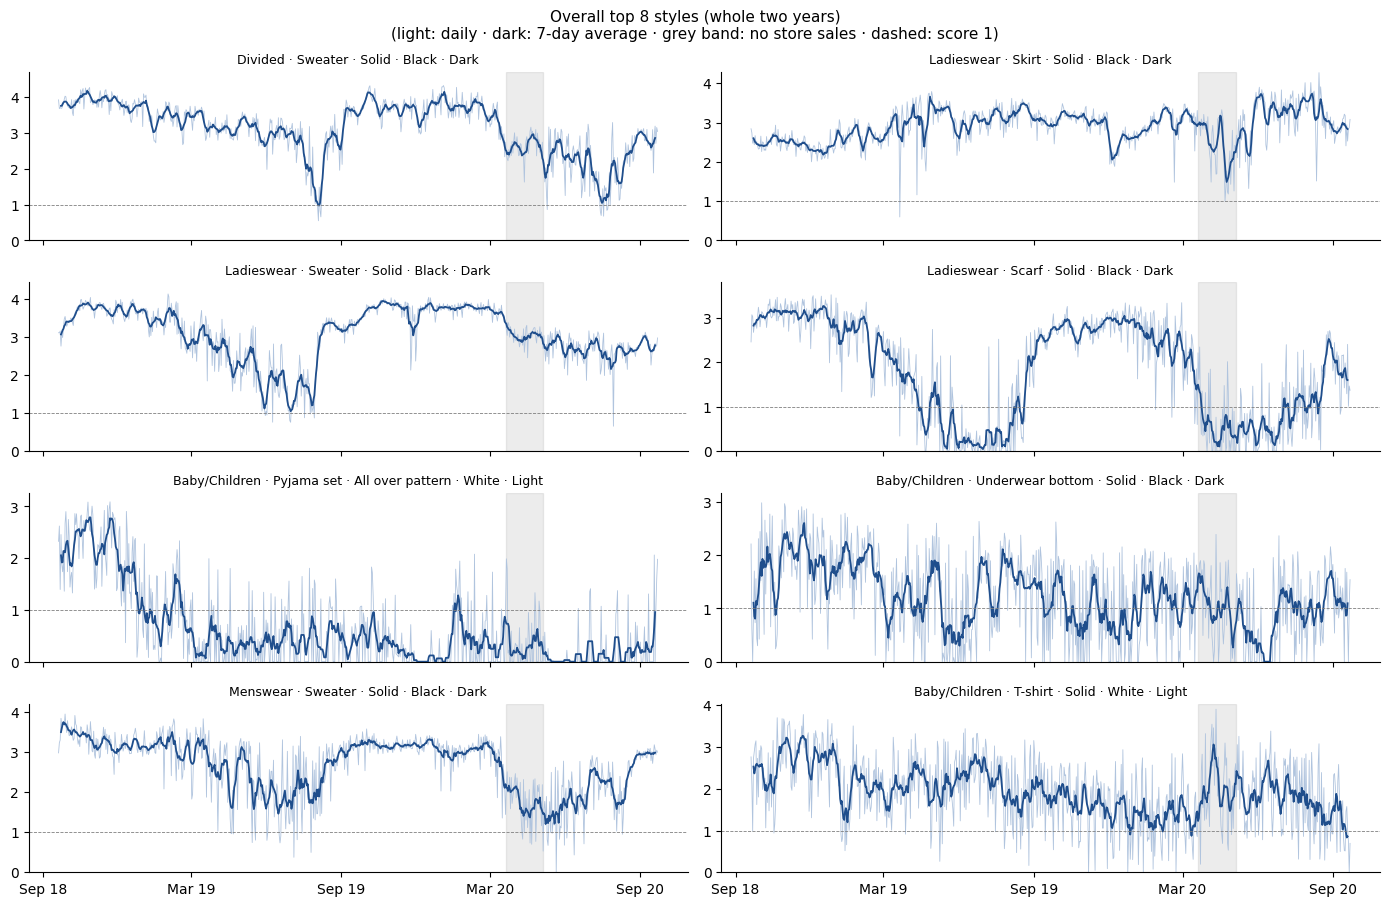

In [4]:
# Styles to look at: the overall winners (whole two years), plus seasonal and all-year product types
overall = success_scores(tx, styled, START, END)
TOP = overall.head(8).style_id.tolist()
def top_of_type(t, n=2):
    return overall[overall.style_name.str.contains(f"· {t} ·", regex=False)].head(n).style_id.tolist()
SEASONAL = top_of_type("Coat") + top_of_type("Sweater") + top_of_type("Swimwear bottom") + top_of_type("Shorts")
ALL_YEAR = top_of_type("Trousers") + top_of_type("T-shirt") + top_of_type("Bra") + top_of_type("Socks")

names = overall.set_index("style_id").style_name
days = pd.date_range(START, END)
series = (daily.pivot(index="t_dat", columns="style_id", values="success_score")
               .reindex(days).fillna(0))   # no sales on a day → score 0


def small_multiples(ids, title, ncols=2):
    nrows = int(np.ceil(len(ids) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(14, 2.3 * nrows), sharex=True)
    for ax, sid in zip(axes.flat, ids):
        ax.plot(series.index, series[sid], color="#B0C4DE", lw=.6)
        ax.plot(series.index, series[sid].rolling(7, center=True).mean(), color="#1f4e8c", lw=1.3)
        ax.axvspan(*COVID, color="grey", alpha=.15)
        ax.axhline(1, color="grey", lw=.6, ls="--")
        ax.set_title(names[sid], fontsize=9)
        ax.set_ylim(0, np.nanpercentile(series[sid], 99.5) * 1.1)
    for ax in axes.flat[len(ids):]:
        ax.set_visible(False)
    for ax in axes[-1]:
        ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[3, 9]))
        ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %y"))
    fig.suptitle(title + "\n(light: daily · dark: 7-day average · grey band: no store sales · dashed: score 1)", fontsize=11)
    plt.tight_layout(); plt.show()


small_multiples(TOP, "Overall top 8 styles (whole two years)")

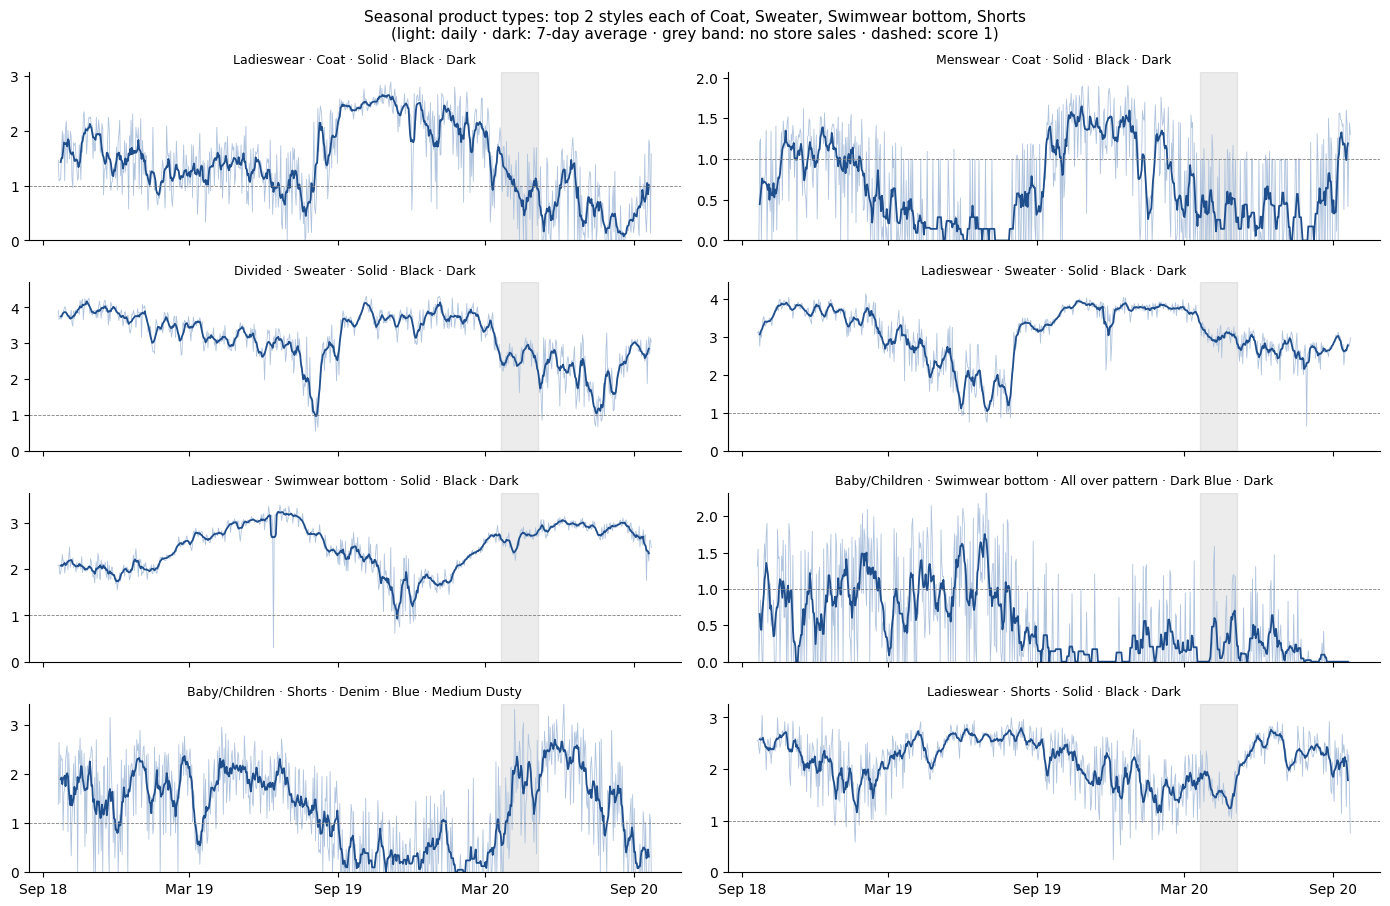

In [5]:
small_multiples(SEASONAL, "Seasonal product types: top 2 styles each of Coat, Sweater, Swimwear bottom, Shorts")

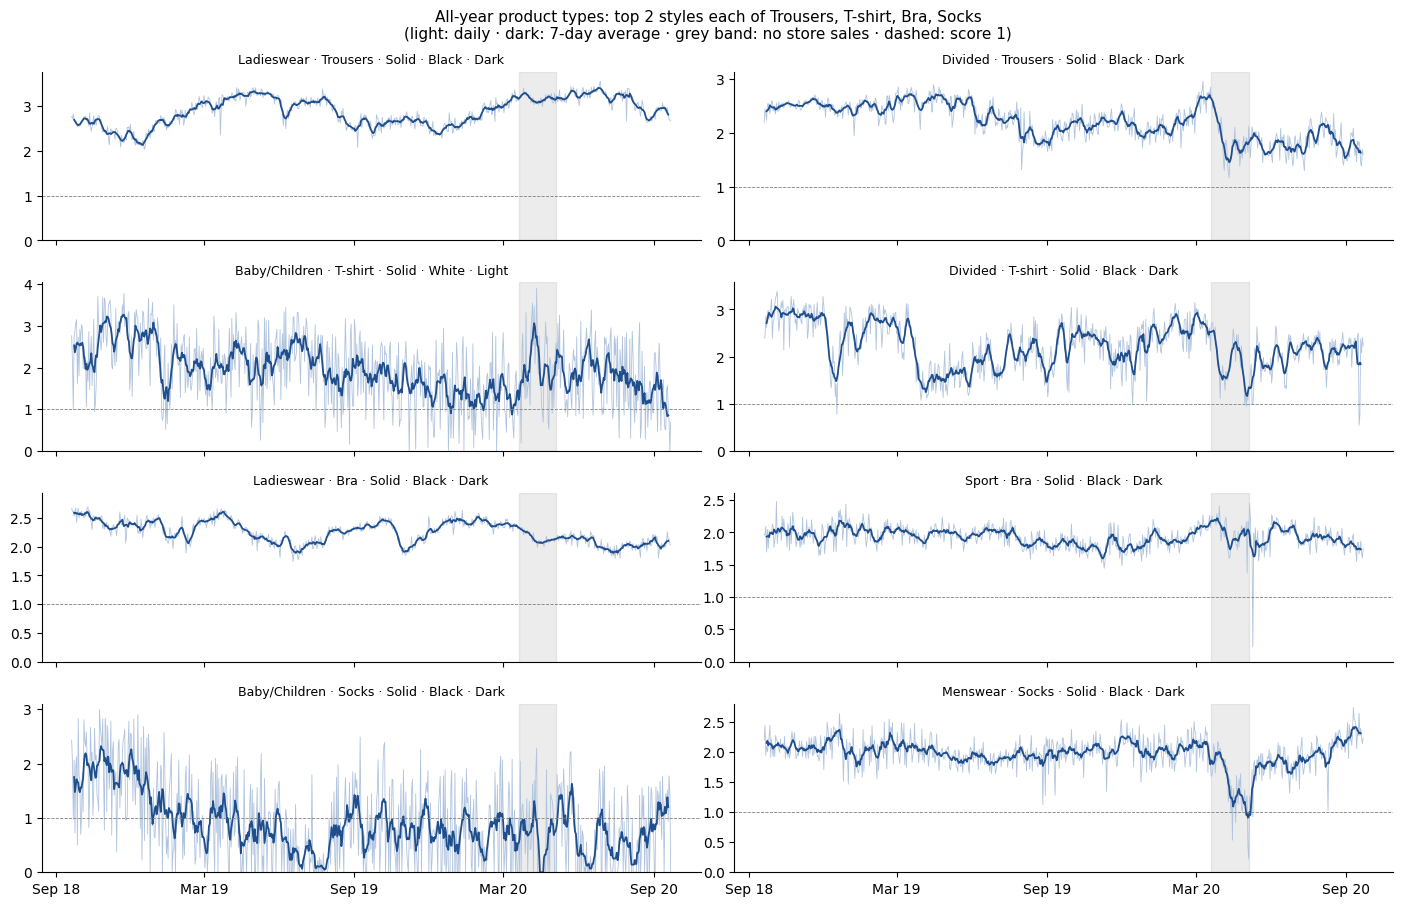

In [6]:
small_multiples(ALL_YEAR, "All-year product types: top 2 styles each of Trousers, T-shirt, Bra, Socks")

## 2. Many styles at once

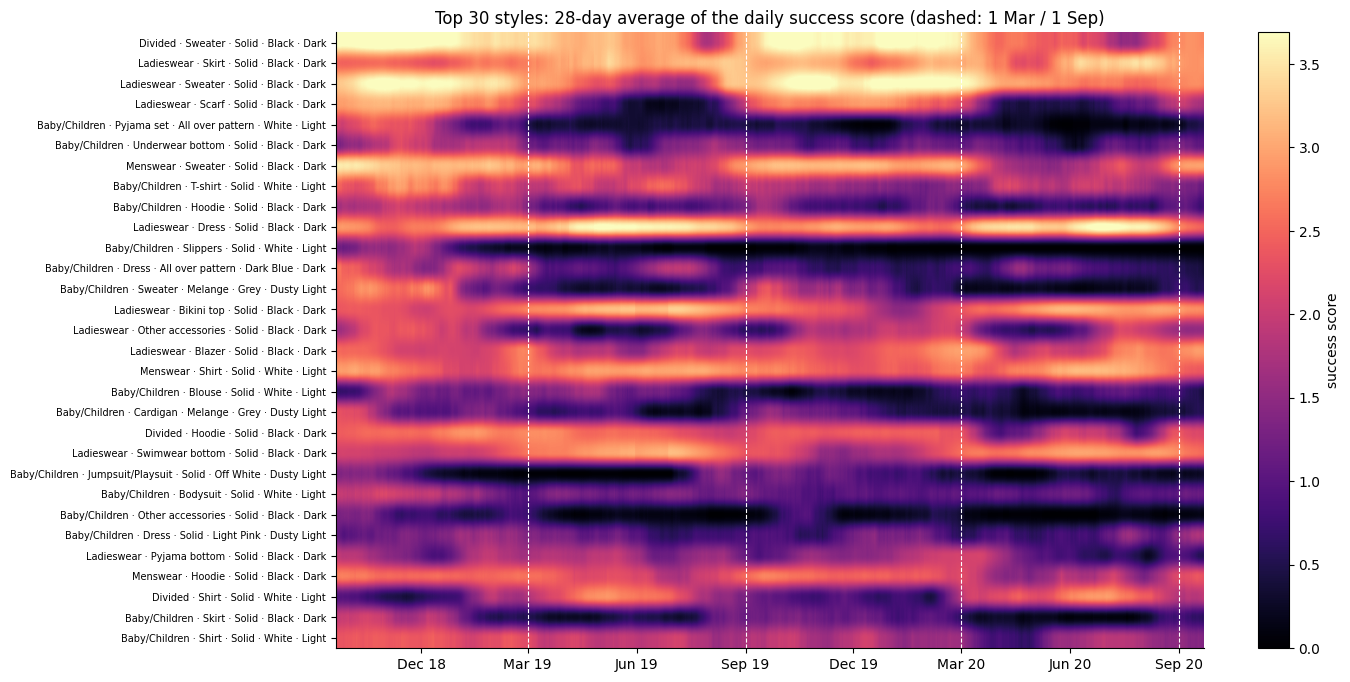

In [7]:
top30 = overall.head(30).style_id
smooth = series[top30].rolling(28, center=True, min_periods=14).mean()
fig, ax = plt.subplots(figsize=(14, 8))
im = ax.imshow(smooth.T.values, aspect="auto", cmap="magma", vmin=0, vmax=np.nanpercentile(smooth.values, 98),
               extent=[mdates.date2num(days[0]), mdates.date2num(days[-1]), len(top30), 0])
ax.set_yticks(np.arange(len(top30)) + .5); ax.set_yticklabels(names[top30], fontsize=7)
ax.xaxis_date(); ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[3, 6, 9, 12]))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %y"))
for x in [pd.Timestamp("2019-03-01"), pd.Timestamp("2019-09-01"), pd.Timestamp("2020-03-01"), pd.Timestamp("2020-09-01")]:
    ax.axvline(mdates.date2num(x), color="white", lw=.8, ls="--")
ax.set_title("Top 30 styles: 28-day average of the daily success score (dashed: 1 Mar / 1 Sep)")
plt.colorbar(im, label="success score"); plt.show()

## 3. Trend and seasonality, measured

For the 300 styles with the highest overall score, using the 28-day average:
- **Seasonality:** correlation between the first year and the second year, aligned by date (364-day shift).
  For contrast, the same correlation with a 182-day shift, i.e. against the *opposite* season.
- **Trend:** average score in year 2 ÷ year 1 (styles that already sold in year 1).

In [8]:
top300 = overall.head(300).style_id
sm = series[top300].rolling(28, center=True, min_periods=14).mean()
y1 = sm.loc["2018-10-04":"2019-09-05"]                 # first year, trimmed for the rolling window
def shifted_corr(shift_days):
    y2 = sm.shift(-shift_days).loc[y1.index]
    return pd.Series({sid: y1[sid].corr(y2[sid]) for sid in top300})

same_season = shifted_corr(364)
opposite_season = shifted_corr(182)
y1_mean, y2_mean = sm.loc[:"2019-09-19"].mean(), sm.loc["2019-09-20":].mean()
trend = (y2_mean / y1_mean)[y1_mean > 0]   # styles that already sold in year 1

summary = pd.DataFrame({
    "corr with same date next year": same_season.describe(),
    "corr with opposite season (182 days later)": opposite_season.describe(),
    "year 2 ÷ year 1 average score": trend.describe(),
}).round(2)
summary

,corr with same date next year,corr with opposite season (182 days later),year 2 ÷ year 1 average score
count,291.00,294.00,295.00
mean,0.43,-0.34,0.98
std,0.44,0.45,1.93
min,-0.86,-0.97,0.00
25%,0.14,-0.71,0.53
50%,0.56,-0.41,0.81
75%,0.80,-0.03,1.00
max,0.98,0.86,28.81


In [9]:
by_type = pd.DataFrame({"same season corr": same_season, "type": overall.set_index("style_id").loc[top300, "style_name"].str.split(" · ").str[1]})
print("most seasonal product types among the top 300 styles (median same-season correlation, ≥3 styles):")
t = by_type.groupby("type")["same season corr"].agg(["median", "size"])
t[t["size"] >= 3].sort_values("median", ascending=False).round(2)

most seasonal product types among the top 300 styles (median same-season correlation, ≥3 styles):


,median,size
type,,
Scarf,0.94,6
Sneakers,0.86,3
Hat/beanie,0.85,8
Hat/brim,0.83,3
Blouse,0.82,5
Swimwear bottom,0.78,7
Sweater,0.78,13
Polo shirt,0.77,4
Sandals,0.77,5


## 4. How long must a period be for the score to be reliable?

**Split-half reliability:** for a period of length *L*, compute each style's score twice, once from the odd days
and once from the even days of the same period, and correlate the two across styles. If the period is long enough,
both halves tell the same story (correlation near 1). If it is too short, the score is mostly noise.

**Data availability:** how many non-overlapping periods of that length the two years contain, and how many of them
have the same period one year earlier (needed for "same season last year").

In [10]:
ad["day_index"] = (ad.t_dat - START).dt.days
ad["parity"] = ad.day_index % 2
rows = []
for L in [7, 14, 28, 56, 91, 182]:
    n_windows = ((END - START).days + 1) // L   # complete windows only
    w = ad[ad.day_index < n_windows * L].assign(window=lambda d: d.day_index // L)
    halves = score(w, ["window", "parity"])
    pv = halves.pivot_table(index=["window", "style_id"], columns="parity", values="success_score").dropna()
    rel = pv.groupby(level="window").apply(lambda g: g[0].corr(g[1], method="spearman"))
    # top-style reliability: of the top 50 by odd days, how many are top 50 by even days
    top_rel = pv.groupby(level="window").apply(
        lambda g: len(set(g[0].nlargest(50).index) & set(g[1].nlargest(50).index)) / 50)
    rows.append({"period (days)": L, "complete periods in data": n_windows,
                 "with same period a year earlier": max(n_windows - int(np.ceil(364 / L)), 0),
                 "split-half Spearman (median)": rel.median(), "split-half top-50 overlap (median)": top_rel.median()})
reliability = pd.DataFrame(rows).round(2)
reliability

,period (days),complete periods in data,with same period a year earlier,split-half Spearman (median),split-half top-50 overlap (median)
0,7,104,52,0.92,0.74
1,14,52,26,0.94,0.80
2,28,26,13,0.95,0.84
3,56,13,6,0.96,0.88
4,91,8,4,0.97,0.90
5,182,4,2,0.97,0.94


## Findings

**Noise**
- Big adult styles (black sweaters, trousers, bras, skirts) have smooth daily scores. Small, mostly Baby/Children
  styles are very noisy day to day.
- Measured noise is low once a period is a few weeks long. Split-half reliability is 0.92 at 7 days, 0.95 at 28 days
  and 0.97 at 91+ days. For the top 50 it rises from 0.74 (7 days) to 0.90 (91 days) and 0.94 (182 days).
  **Noise is not the limiting factor beyond about a month.**

**Seasonality: a clear half-year cycle**
- Sweaters, coats and scarves score high from September to March and drop from April to August.
  Swimwear and shorts do the opposite. The switches line up with the **1 Mar / 1 Sep** boundaries in the heatmap.
- For the top 300 styles, the 28-day score correlates with the same dates a year later (median **+0.56**),
  and *negatively* with the opposite half-year (median **−0.41**).
- The most seasonal types are scarves, hats, sweaters, swimwear, coats and shorts. Basics (bras, tops, leggings,
  bodysuits) show little seasonality.
- **Within a half-year, a style's level is fairly stable.** Most of the change happens at the season switch.

**Trend**
- There's no strong trend. The median style scores 0.81× in year 2 versus year 1. Part of that is COVID: store sales are
  missing on 45 days (2020-03-20 → 2020-05-05), when several styles dip.

**Data availability**
- 182-day periods: 4 in the data, only 2 of them with the same season a year earlier.
- 91-day periods: 8, of which 4 have the same period a year earlier.